# Olist E-Commerce: Business Analysis

**Scenario.** You are a data analyst at Olist, a Brazilian marketplace. Management asks:
*how is the business doing, and where are the problems?*

**Approach.** Load the 8 Kaggle CSVs into SQLite, answer each question with SQL
(`sql/queries.sql`), cross-check key numbers with pandas, then chart the findings.

Run from the project root: `python analysis.py` (put the CSVs in `data/raw/`,
or set the `OLIST_RAW` environment variable to another folder).

In [1]:
import os
import re
import sqlite3
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

if "__file__" in globals():                    # run as a script
    BASE = Path(__file__).resolve().parent
else:                                          # run as a notebook (from the project root or notebooks/)
    BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = Path(os.environ.get("OLIST_RAW", BASE / "data" / "raw"))
TABLES_DIR = BASE / "outputs" / "tables"
CHARTS_DIR = BASE / "outputs" / "charts"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

## 1. Load the data into SQLite

Two product categories are missing from the translation file, so I add them by hand.

In [2]:
con = sqlite3.connect(":memory:")
for table, fname in FILES.items():
    pd.read_csv(RAW / fname, encoding="utf-8-sig").to_sql(table, con, index=False)

pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers"],
}).to_sql("category_translation", con, if_exists="append", index=False)

for table in FILES:
    n = con.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
    print(f"{table:22s}{n:>9,} rows")

customers                99,441 rows
orders                   99,441 rows
order_items             112,650 rows
order_payments          103,886 rows
order_reviews            99,224 rows
products                 32,951 rows
sellers                   3,095 rows
category_translation         73 rows


## 2. Run the SQL queries

Each block in `sql/queries.sql` starts with `-- name: <id>`. The `setup` block creates
the cleaning views; every other block returns one result table.

In [3]:
sql_text = (BASE / "sql" / "queries.sql").read_text(encoding="utf-8")
parts = re.split(r"^-- name: (\w+)\s*$", sql_text, flags=re.M)
blocks = dict(zip(parts[1::2], parts[2::2]))

con.executescript(blocks.pop("setup"))

results = {}
for name, query in blocks.items():
    results[name] = pd.read_sql_query(query, con)
    results[name].to_csv(TABLES_DIR / f"{name}.csv", index=False)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
for name, df in results.items():
    print(f"\n--- {name} ---")
    print(df.to_string(index=False))


--- q01_kpi_summary ---
 delivered_orders  unique_customers  revenue_brl  avg_order_value  freight_pct_of_revenue  avg_delivery_days  late_pct
            96470             93350  13220248.93           137.04                    16.6               12.6       6.8

--- q02_monthly_trend ---
purchase_month  orders   revenue  avg_order_value  revenue_mom_pct
       2017-01     750 111798.36           149.06              NaN
       2017-02    1653 234223.40           141.70            109.5
       2017-03    2546 359198.85           141.08             53.4
       2017-04    2303 340669.68           147.92             -5.2
       2017-05    3545 489159.25           137.99             43.6
       2017-06    3135 421923.37           134.58            -13.7
       2017-07    3872 481604.52           124.38             14.1
       2017-08    4193 554699.70           132.29             15.2
       2017-09    4150 607399.67           146.36              9.5
       2017-10    4478 648247.65        

## 3. Cross-check the headline numbers with pandas

Never trust a single tool: recompute the KPIs independently from the raw CSVs.

In [4]:
orders = pd.read_csv(RAW / FILES["orders"], parse_dates=[
    "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"])
items = pd.read_csv(RAW / FILES["order_items"])
customers = pd.read_csv(RAW / FILES["customers"])

deliv = orders[(orders.order_status == "delivered") & orders.order_delivered_customer_date.notna()]
deliv = deliv[deliv.order_id.isin(items.order_id)]          # same population as SQL (has items)

kpi = results["q01_kpi_summary"].iloc[0]
pd_revenue = items[items.order_id.isin(deliv.order_id)].price.sum()
pd_late = (deliv.order_delivered_customer_date.dt.normalize()
           > deliv.order_estimated_delivery_date.dt.normalize()).mean() * 100
per_customer = deliv.merge(customers, on="customer_id").groupby("customer_unique_id").size()
pd_repeat = (per_customer > 1).mean() * 100
sql_repeat = results["q07_repeat_customers"].query("segment != '1 order'").pct_of_customers.sum()

checks = {
    "delivered orders": (len(deliv), kpi.delivered_orders, 0),
    "revenue (BRL)": (pd_revenue, kpi.revenue_brl, 1),
    "late %": (pd_late, kpi.late_pct, 0.1),
    "repeat customers %": (pd_repeat, sql_repeat, 0.15),
}
for label, (a, b, tol) in checks.items():
    ok = abs(a - b) <= tol
    print(f"{'OK  ' if ok else 'FAIL'} {label:20s} pandas={a:,.2f}  sql={b:,.2f}")
    assert ok, f"pandas and SQL disagree on {label}"

OK   delivered orders     pandas=96,470.00  sql=96,470.00
OK   revenue (BRL)        pandas=13,220,248.93  sql=13,220,248.93
OK   late %               pandas=6.77  sql=6.80
OK   repeat customers %   pandas=3.00  sql=3.00


## 4. Charts

One idea per chart, the title states the finding.

In [5]:
INK, MUTED, GRID, SURFACE, BLUE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb", "#2a78d6"
plt.rcParams.update({"font.size": 10, "axes.titlesize": 13})


def new_chart(title, grid_axis="y", figsize=(9, 4.8)):
    fig, ax = plt.subplots(figsize=figsize, facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_title(title, loc="left", color=INK, fontweight="bold", pad=14)
    return fig, ax


def save(fig, name):
    fig.tight_layout()
    fig.savefig(CHARTS_DIR / f"{name}.png", dpi=150, facecolor=SURFACE)
    if matplotlib.get_backend().lower() != "agg":
        plt.show()
    plt.close(fig)


def money(v):
    return f"R$ {v / 1e6:.2f}M" if v >= 1e6 else f"R$ {v / 1e3:.0f}K"

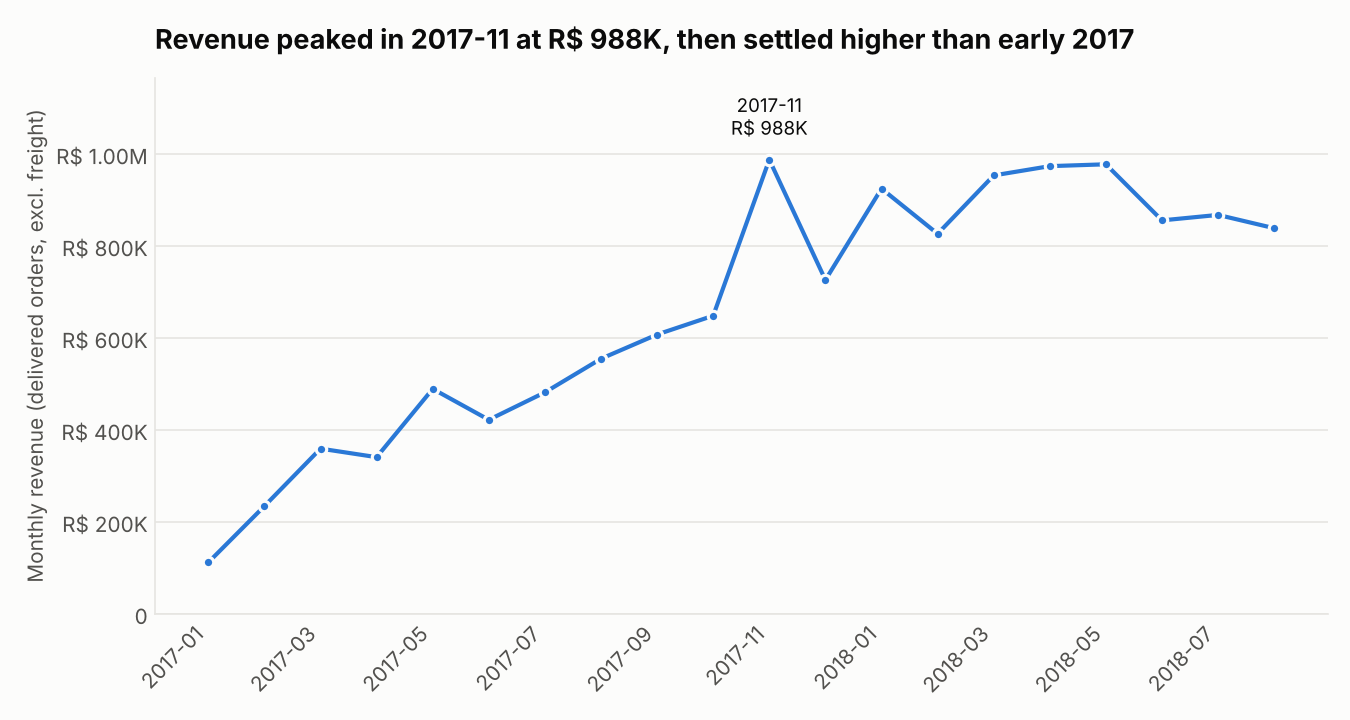

In [6]:
# Chart 1: monthly revenue (only complete months)
full = results["q02_monthly_trend"]          # already limited to complete months in SQL
peak = full.loc[full.revenue.idxmax()]

fig, ax = new_chart(f"Revenue peaked in {peak.purchase_month} at {money(peak.revenue)}, then settled higher than early 2017")
ax.plot(full.purchase_month, full.revenue, color=BLUE, linewidth=2, marker="o", markersize=5,
        markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.annotate(f"{peak.purchase_month}\n{money(peak.revenue)}", (peak.purchase_month, peak.revenue),
            xytext=(0, 12), textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.set_xticks(range(0, len(full), 2))
ax.set_xticklabels(full.purchase_month.iloc[::2], rotation=45, ha="right")
ax.set_ylim(0, peak.revenue * 1.18)
ax.yaxis.set_major_formatter(lambda v, _: money(v) if v else "0")
ax.set_ylabel("Monthly revenue (delivered orders, excl. freight)", color=MUTED)
save(fig, "01_monthly_revenue")

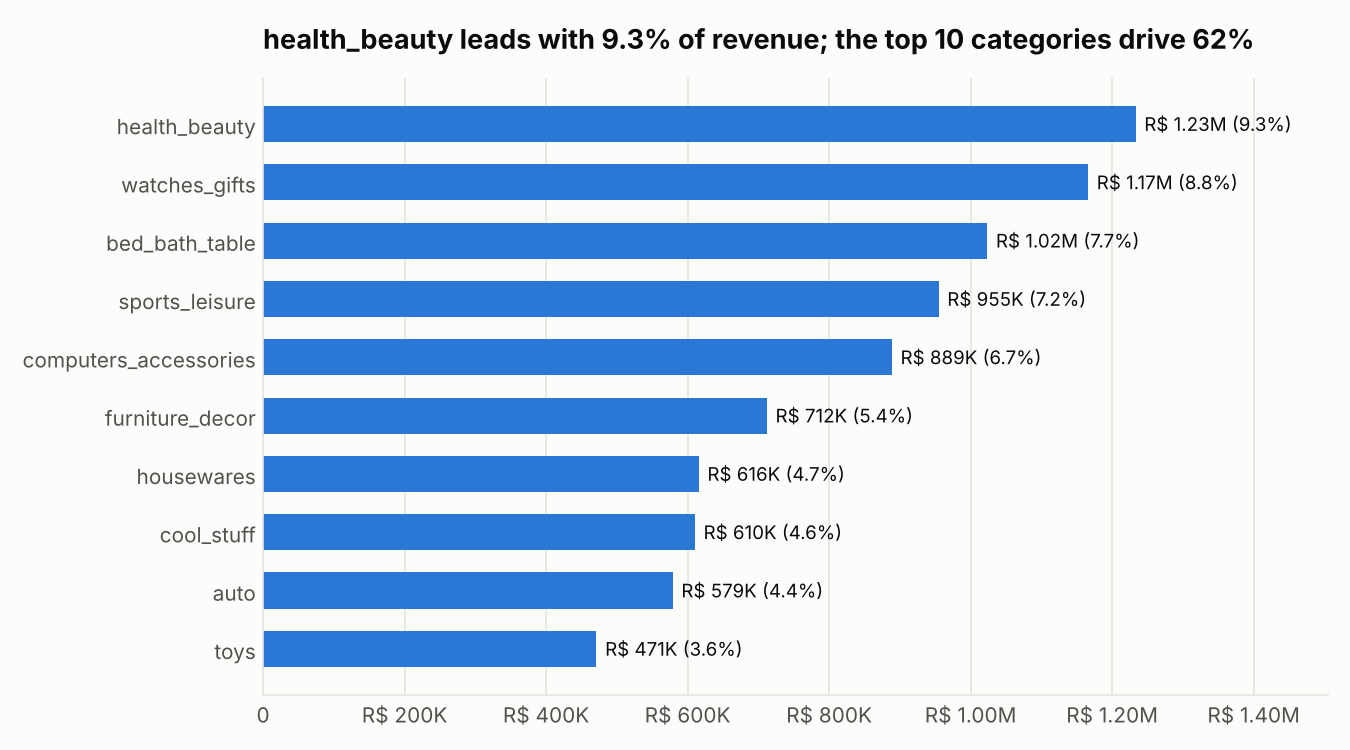

In [7]:
# Chart 2: top categories
cats = results["q03_top_categories"].sort_values("revenue")
top = cats.iloc[-1]
fig, ax = new_chart(f"{top.category} leads with {top.revenue_share_pct:.1f}% of revenue; the top 10 categories drive "
                    f"{cats.revenue_share_pct.sum():.0f}%", grid_axis="x", figsize=(9, 5))
ax.barh(cats.category, cats.revenue, color=BLUE, height=0.62)
for y, (v, s) in enumerate(zip(cats.revenue, cats.revenue_share_pct)):
    ax.text(v + cats.revenue.max() * 0.01, y, f"{money(v)} ({s:.1f}%)", va="center", color=INK, fontsize=9)
ax.set_xlim(0, cats.revenue.max() * 1.22)
ax.xaxis.set_major_formatter(lambda v, _: money(v) if v else "0")
save(fig, "02_top_categories")

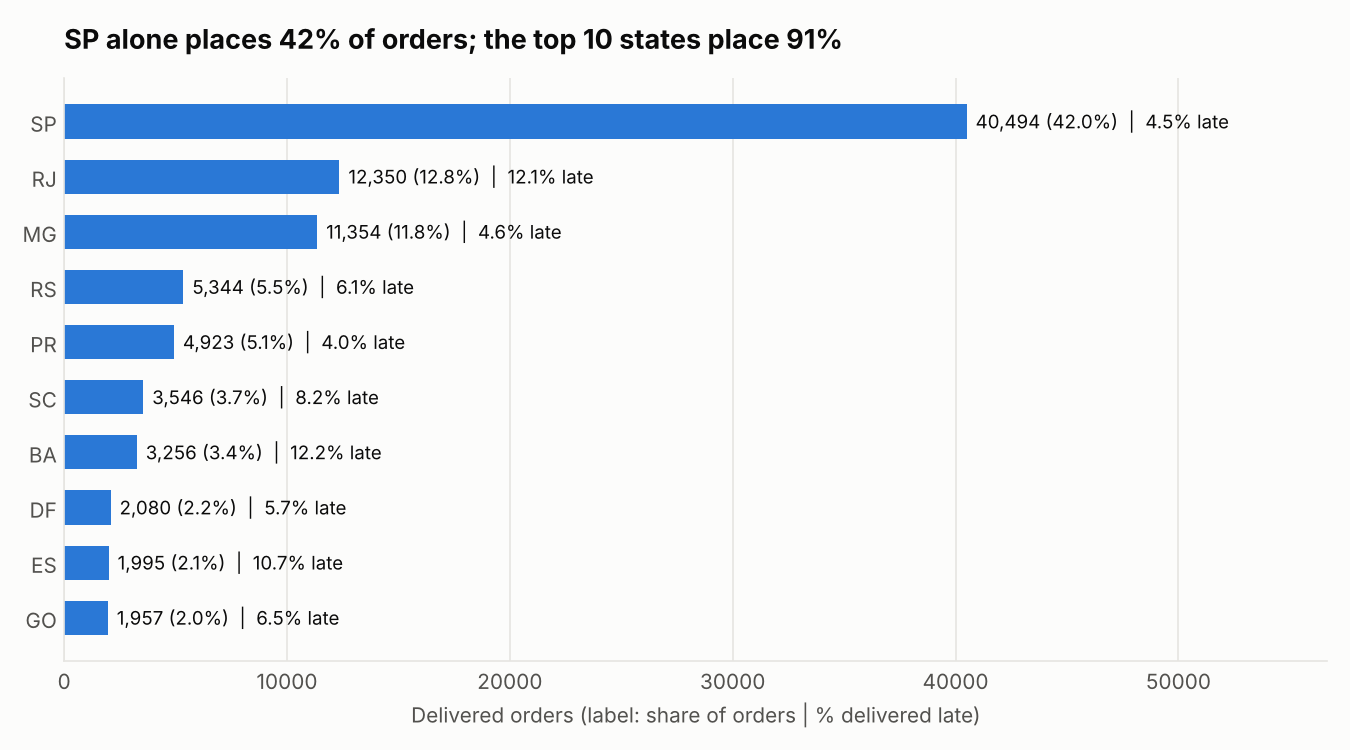

In [8]:
# Chart 3: orders by state
states = results["q04_state_summary"].head(10).sort_values("orders")
sp = states.iloc[-1]
fig, ax = new_chart(f"{sp.customer_state} alone places {sp.order_share_pct:.0f}% of orders; "
                    f"the top 10 states place {states.order_share_pct.sum():.0f}%", grid_axis="x", figsize=(9, 5))
ax.barh(states.customer_state, states.orders, color=BLUE, height=0.62)
for y, (v, s, late) in enumerate(zip(states.orders, states.order_share_pct, states.late_pct)):
    ax.text(v + states.orders.max() * 0.01, y, f"{v:,} ({s:.1f}%)  |  {late:.1f}% late", va="center",
            color=INK, fontsize=9)
ax.set_xlim(0, states.orders.max() * 1.4)
ax.set_xlabel("Delivered orders (label: share of orders | % delivered late)", color=MUTED)
save(fig, "03_orders_by_state")

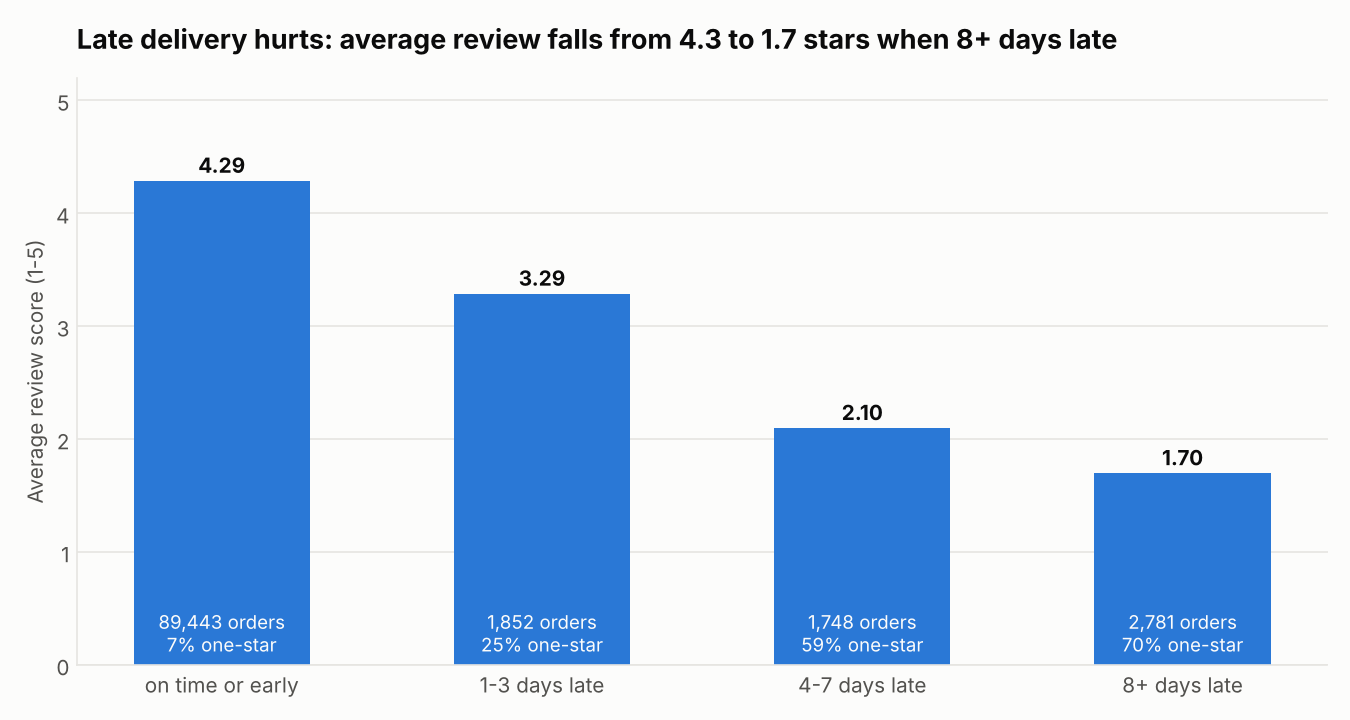

In [9]:
# Chart 4: delivery vs review
dv = results["q06_delivery_vs_review"]
best, worst = dv.iloc[0], dv.iloc[-1]
fig, ax = new_chart(f"Late delivery hurts: average review falls from {best.avg_review_score:.1f} "
                    f"to {worst.avg_review_score:.1f} stars when 8+ days late")
labels = dv.delivery_bucket.str.replace(r"^\d\. ", "", regex=True)
ax.bar(labels, dv.avg_review_score, color=BLUE, width=0.55)
for x, (score, n, one) in enumerate(zip(dv.avg_review_score, dv.orders, dv.one_star_pct)):
    ax.text(x, score + 0.07, f"{score:.2f}", ha="center", color=INK, fontweight="bold")
    ax.text(x, 0.12, f"{n:,} orders\n{one:.0f}% one-star", ha="center", color=SURFACE, fontsize=9)
ax.set_ylim(0, 5.2)
ax.set_ylabel("Average review score (1-5)", color=MUTED)
save(fig, "04_delivery_vs_review")


Done. Tables -> /home/claude/olist_project/outputs/tables | Charts -> /home/claude/olist_project/outputs/charts


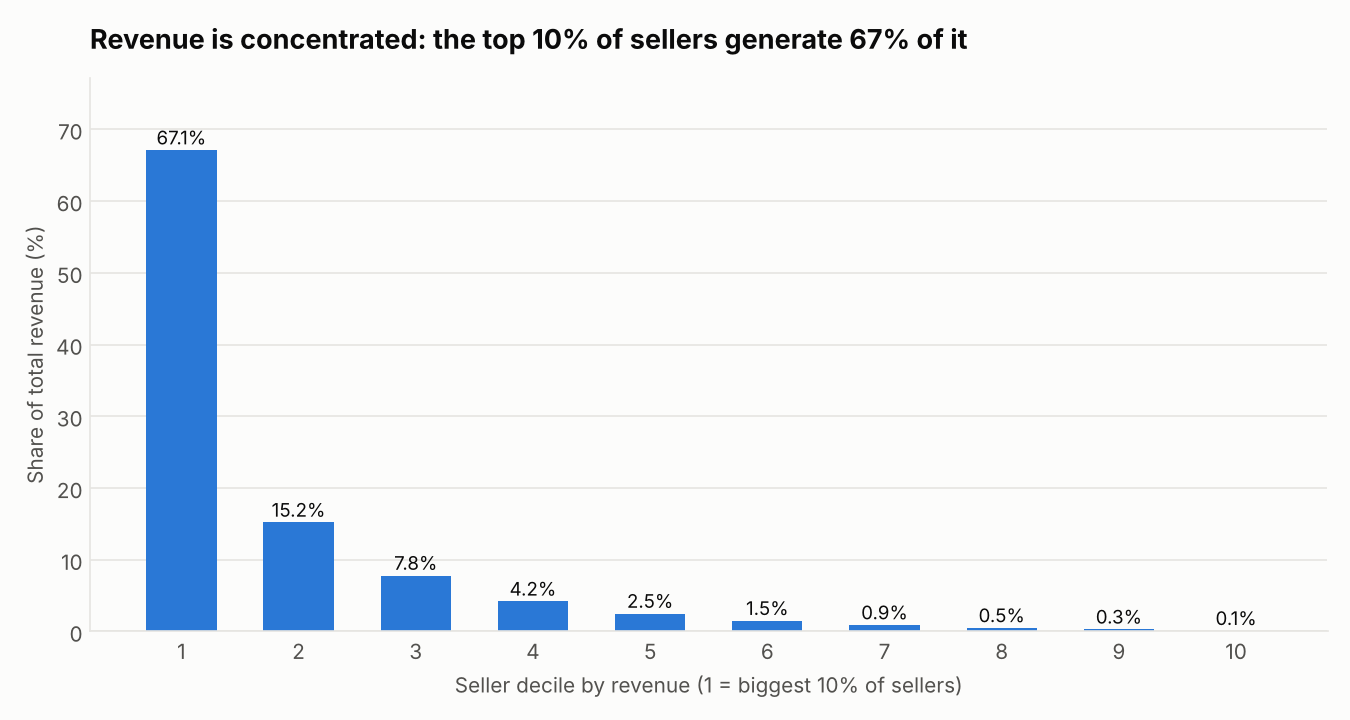

In [10]:
# Chart 5: seller concentration
sel = results["q08_seller_pareto"]
top_dec = sel.iloc[0]
fig, ax = new_chart(f"Revenue is concentrated: the top 10% of sellers generate {top_dec.revenue_share_pct:.0f}% of it")
ax.bar(sel.decile.astype(str), sel.revenue_share_pct, color=BLUE, width=0.6)
for x, v in enumerate(sel.revenue_share_pct):
    ax.text(x, v + 0.8, f"{v:.1f}%", ha="center", color=INK, fontsize=9)
ax.set_ylim(0, sel.revenue_share_pct.max() * 1.15)
ax.set_xlabel("Seller decile by revenue (1 = biggest 10% of sellers)", color=MUTED)
ax.set_ylabel("Share of total revenue (%)", color=MUTED)
save(fig, "05_seller_concentration")

print("\nDone. Tables ->", TABLES_DIR, "| Charts ->", CHARTS_DIR)